# ShopMaster · Modelo de predicción de precios (Minería de Datos II)

**Problema analítico:** regresión supervisada para pronosticar el **precio** de productos de consumo masivo en los próximos años.

| Elemento | Definición |
|---|---|
| Tipo de problema | Regresión supervisada (series de precios por producto) |
| **Variable predictiva (a predecir)** | `precio` (COP) |
| Variables predictoras | `año` (numérica) y `producto` (categórica, 22 productos) |
| Dataset | Kaggle · *Productos de Consumo Masivo* (precios anuales 2015-2024, archivo `Dataset_final.arff`) |
| Integración | El notebook exporta `modelo_precios.json`; el backend Spring Boot lo carga y predice en vivo para la web y la app móvil |

**Flujo:** carga → exploración → preparación → modelado y comparación (validación temporal) → selección → exportación.

In [1]:
import re, json, io, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
SEED = 7

## 1. Carga del dataset
En Google Colab se te pedirá subir `Dataset_final.arff` (está en el repositorio, carpeta `ml/`). Si el archivo ya está junto al notebook, se usa directamente.

In [2]:
RUTA = "Dataset_final.arff"
if not os.path.exists(RUTA):
    try:
        from google.colab import files          # solo existe en Colab
        subido = files.upload()
        RUTA = next(iter(subido))
    except ImportError:
        raise FileNotFoundError("Coloca Dataset_final.arff junto al notebook")

def leer_arff(ruta):
    filas, datos = [], False
    with open(ruta, encoding="utf-8-sig") as f:
        for linea in f:
            linea = linea.strip()
            if linea.lower() == "@data":
                datos = True
                continue
            if datos and linea:
                m = re.match(r"(\d+),('?)(.*?)\2,([\d.]+)$", linea)
                filas.append((int(m[1]), m[3], float(m[4])))
    return pd.DataFrame(filas, columns=["anio", "producto", "precio"])

df = leer_arff(RUTA)
df.head()

,anio,producto,precio
0,2015,Gaseosa Postobón 1.5L,4253.51
1,2016,Gaseosa Postobón 1.5L,4663.73
2,2017,Gaseosa Postobón 1.5L,4872.53
3,2018,Gaseosa Postobón 1.5L,5018.92
4,2019,Gaseosa Postobón 1.5L,5259.42


## 2. Exploración de los datos

In [3]:
print("Filas, columnas:", df.shape)
print("Productos:", df.producto.nunique(), "| Años:", df.anio.min(), "-", df.anio.max())
print("Valores nulos:\n", df.isna().sum().to_string())
print("Filas duplicadas:", df.duplicated(["anio", "producto"]).sum())
print("Observaciones por producto:", df.groupby("producto").size().unique())
df.describe().round(2)

Filas, columnas: (220, 3)
Productos: 22 | Años: 2015 - 2024
Valores nulos:
 anio        0
producto    0
precio      0
Filas duplicadas: 0
Observaciones por producto: [10]


,anio,precio
count,220.00,220.00
mean,2019.50,6506.46
std,2.88,2789.92
min,2015.00,2105.67
25%,2017.00,4003.79
50%,2019.50,6308.72
75%,2022.00,8534.35
max,2024.00,13952.61


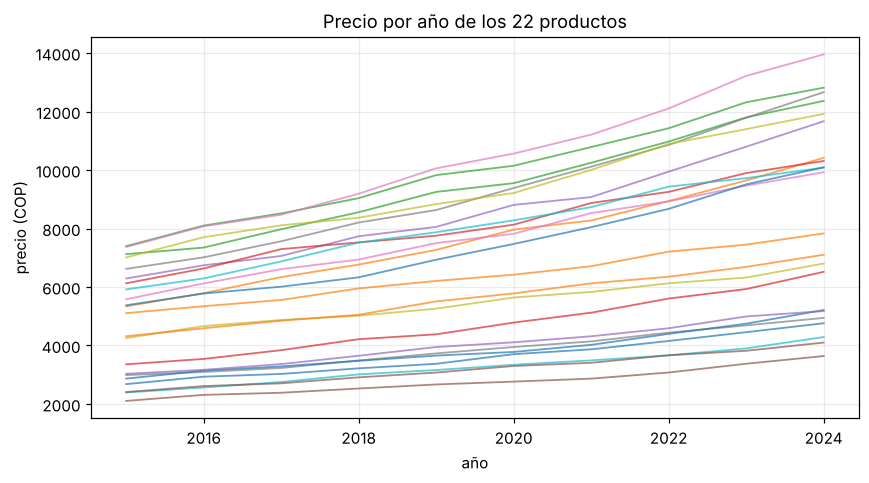

Crecimiento anual compuesto por producto (%):
count    22.00
mean      6.46
std       0.75
min       4.87
25%       6.08
50%       6.31
75%       7.05
max       7.71


In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for p, g in df.groupby("producto"):
    ax.plot(g.anio, g.precio, alpha=.7, lw=1.2)
ax.set_title("Precio por año de los 22 productos"); ax.set_xlabel("año"); ax.set_ylabel("precio (COP)")
plt.show()

crec = df.sort_values("anio").groupby("producto").precio.apply(lambda s: (s.iloc[-1] / s.iloc[0]) ** (1 / (df.anio.nunique() - 1)) - 1)
print("Crecimiento anual compuesto por producto (%):")
print((crec * 100).describe().round(2).to_string())

**Lectura.** Los precios crecen de forma sostenida y casi exponencial (~6,5 % anual en promedio). Cada producto tiene su propio nivel y su propia pendiente, por lo que un único modelo lineal global (misma pendiente para todos) pierde precisión. Además, trabajar con el **logaritmo del precio** vuelve lineal el crecimiento porcentual constante.

**Limitación a declarar:** son solo 10 puntos por producto (220 filas) y las series son muy suaves; los R² altos son esperables y no equivalen a poder predecir shocks (p. ej. la inflación de 2022).

## 3. Preparación de los datos
* Se verifican tipos, nulos y duplicados (arriba: sin nulos ni duplicados).
* `año` se centra en el primer año (`x = año - 2015`).
* `producto` se codifica *one-hot* para los modelos globales.
* Se prueba el `log(precio)` como variable objetivo (el error pasa a ser relativo).

**Validación temporal.** Como el objetivo es pronosticar el futuro, **no se usa una partición aleatoria**:
* *Hold-out*: entrena con 2015-2021 y evalúa con 2022-2024 (pronóstico a 3 años).
* *Rolling-origin*: para cada año de 2020 a 2024 entrena con los años anteriores y predice ese año (pronóstico a 1 año).

In [5]:
PRODUCTOS = sorted(df.producto.unique())
ANIO_BASE = int(df.anio.min())

def matriz(d):
    onehot = pd.get_dummies(d.producto).reindex(columns=PRODUCTOS, fill_value=0).astype(float)
    return np.column_stack([(d.anio.values - ANIO_BASE).astype(float), onehot.values])

def metricas(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** .5,
            "MAPE": float(np.mean(np.abs((y - p) / y)) * 100), "R2": r2_score(y, p)}

## 4. Modelado y comparación

In [6]:
class PorProducto:
    """Una regresión lineal por producto; con log=True ajusta log(precio) (crecimiento exponencial)."""
    def __init__(self, log=False): self.log = log
    def fit(self, d):
        self.m = {}
        for p, g in d.groupby("producto"):
            y = np.log(g.precio) if self.log else g.precio
            self.m[p] = LinearRegression().fit(g[["anio"]], y)
        return self
    def predict(self, d):
        out = []
        for a, p in zip(d.anio, d.producto):
            v = self.m[p].predict(pd.DataFrame({"anio": [a]}))[0]
            out.append(np.exp(v) if self.log else v)
        return np.array(out)

class Global:
    """Modelo único sobre año + producto (one-hot)."""
    def __init__(self, crear, log=False, escalar=False): self.crear, self.log, self.escalar = crear, log, escalar
    def fit(self, d):
        Xt = matriz(d); y = np.log(d.precio.values) if self.log else d.precio.values
        if self.escalar:
            self.sx = StandardScaler().fit(Xt); Xt = self.sx.transform(Xt)
            self.my, self.sy = y.mean(), y.std(); y = (y - self.my) / self.sy
        self.modelo = self.crear().fit(Xt, y); return self
    def predict(self, d):
        Xt = matriz(d)
        if self.escalar: Xt = self.sx.transform(Xt)
        p = self.modelo.predict(Xt)
        if self.escalar: p = p * self.sy + self.my
        return np.exp(p) if self.log else p

MODELOS = {
    "Regresión lineal global (año + producto)": lambda: Global(LinearRegression),
    "Regresión lineal por producto": lambda: PorProducto(False),
    "Regresión log-lineal por producto": lambda: PorProducto(True),
    "Ridge global (log precio)": lambda: Global(lambda: Ridge(alpha=1.0), log=True),
    "Random Forest": lambda: Global(lambda: RandomForestRegressor(300, random_state=SEED)),
    "Gradient Boosting": lambda: Global(lambda: GradientBoostingRegressor(random_state=SEED)),
    "Red neuronal MLP (log precio)": lambda: Global(
        lambda: MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", solver="lbfgs", max_iter=5000, random_state=SEED),
        log=True, escalar=True),
}

entrenamiento, prueba = df[df.anio <= 2021], df[df.anio >= 2022]
holdout, rolling = {}, {}
for nombre, crear in MODELOS.items():
    holdout[nombre] = metricas(prueba.precio.values, crear().fit(entrenamiento).predict(prueba))
    ys, ps = [], []
    for anio in range(2020, 2025):
        previo, objetivo = df[df.anio < anio], df[df.anio == anio]
        ps += list(crear().fit(previo).predict(objetivo)); ys += list(objetivo.precio)
    rolling[nombre] = metricas(np.array(ys), np.array(ps))

tabla = pd.DataFrame(holdout).T.round(3).sort_values("MAPE")
tabla["Precisión % (100 - MAPE)"] = (100 - tabla["MAPE"]).round(2)
print("Hold-out temporal (entrena 2015-2021, prueba 2022-2024):")
tabla

Hold-out temporal (entrena 2015-2021, prueba 2022-2024):


,MAE,RMSE,MAPE,R2,Precisión % (100 - MAPE)
Regresión log-lineal por producto,165.501,225.350,2.146,0.995,97.85
Regresión lineal por producto,311.519,406.266,3.827,0.983,96.17
Red neuronal MLP (log precio),352.003,443.519,4.458,0.980,95.54
Ridge global (log precio),515.826,630.709,6.474,0.959,93.53
Regresión lineal global (año + producto),842.820,989.682,11.294,0.900,88.71
Random Forest,1052.558,1312.745,11.763,0.824,88.24
Gradient Boosting,1245.511,1637.617,12.857,0.726,87.14


In [7]:
print("Rolling-origin a 1 año (2020-2024):")
pd.DataFrame(rolling).T.round(3).sort_values("MAPE")

Rolling-origin a 1 año (2020-2024):


,MAE,RMSE,MAPE,R2
Regresión log-lineal por producto,127.456,163.064,1.748,0.997
Red neuronal MLP (log precio),163.478,212.871,2.304,0.995
Regresión lineal por producto,178.338,233.360,2.336,0.994
Random Forest,508.006,661.170,5.742,0.951
Ridge global (log precio),447.448,531.839,6.260,0.968
Gradient Boosting,806.485,1048.803,9.158,0.877
Regresión lineal global (año + producto),641.290,745.356,9.654,0.938


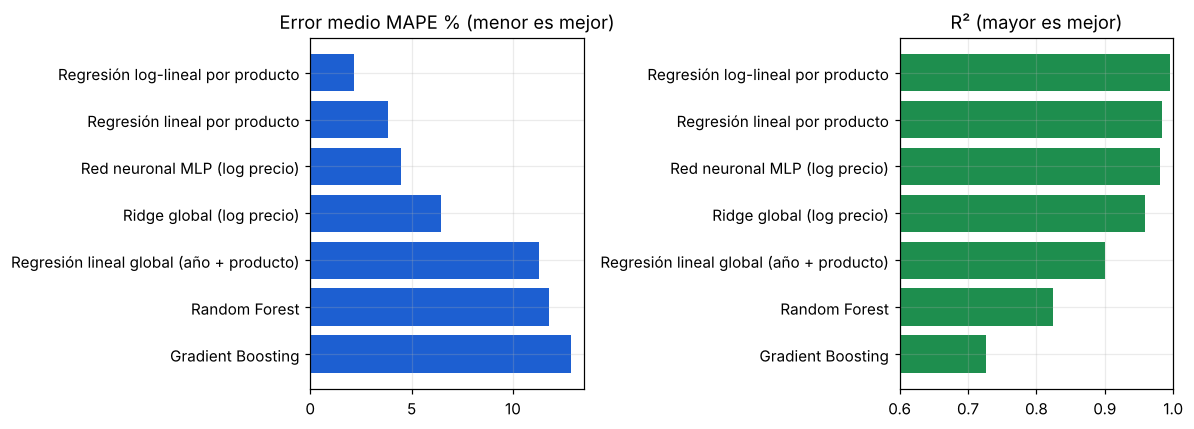

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
orden = tabla.index[::-1]
ax[0].barh(orden, tabla.loc[orden, "MAPE"], color="#1D5FD1"); ax[0].set_title("Error medio MAPE % (menor es mejor)")
ax[1].barh(orden, tabla.loc[orden, "R2"], color="#1E8E4E"); ax[1].set_title("R² (mayor es mejor)"); ax[1].set_xlim(.6, 1)
plt.tight_layout(); plt.show()

**Lectura.** Los modelos de árboles (*Random Forest*, *Gradient Boosting*) rinden peor porque **no extrapolan**: al pronosticar años posteriores a los de entrenamiento repiten el último nivel observado. Los modelos que capturan la tendencia por producto (regresión log-lineal y red neuronal) son los mejores. La red neuronal se mantiene competitiva, pero con solo 10 puntos por producto la regresión log-lineal es más estable y explicable.

## 5. Selección del modelo y porcentaje predictivo
Se elige el modelo con menor MAPE en el hold-out temporal. El **porcentaje predictivo** que se muestra al usuario es `100 − MAPE` del hold-out (precisión media a 3 años) y se acompaña del **R²**. Para el intervalo de cada pronóstico se usa la desviación estándar de los errores en escala logarítmica del hold-out.

In [9]:
MEJOR = tabla.index[0]
print("Modelo seleccionado:", MEJOR)

# Errores logarítmicos del hold-out del modelo seleccionado -> sigma para el intervalo de confianza
pred_ho = MODELOS[MEJOR]().fit(entrenamiento).predict(prueba)
err_log = np.log(prueba.precio.values) - np.log(pred_ho)
SIGMA = float(np.std(err_log, ddof=1))
print("Sigma (log) del hold-out:", round(SIGMA, 4))

# Detalle por producto en el hold-out
det = prueba.assign(pred=pred_ho).groupby("producto").apply(
    lambda g: float(np.mean(np.abs((g.precio - g.pred) / g.precio)) * 100)).round(2)
print("MAPE por producto (hold-out): mín", det.min(), "| máx", det.max())
det.sort_values().tail(5)

Modelo seleccionado: Regresión log-lineal por producto
Sigma (log) del hold-out: 0.0287
MAPE por producto (hold-out): mín 0.62 | máx 5.85


producto
Sprite 1.5L             3.31
Tostadas Bimbo          3.49
Detergente Ariel 1kg    4.14
Suavitel 1L             4.19
Leche Alquería 1L       5.85
dtype: float64

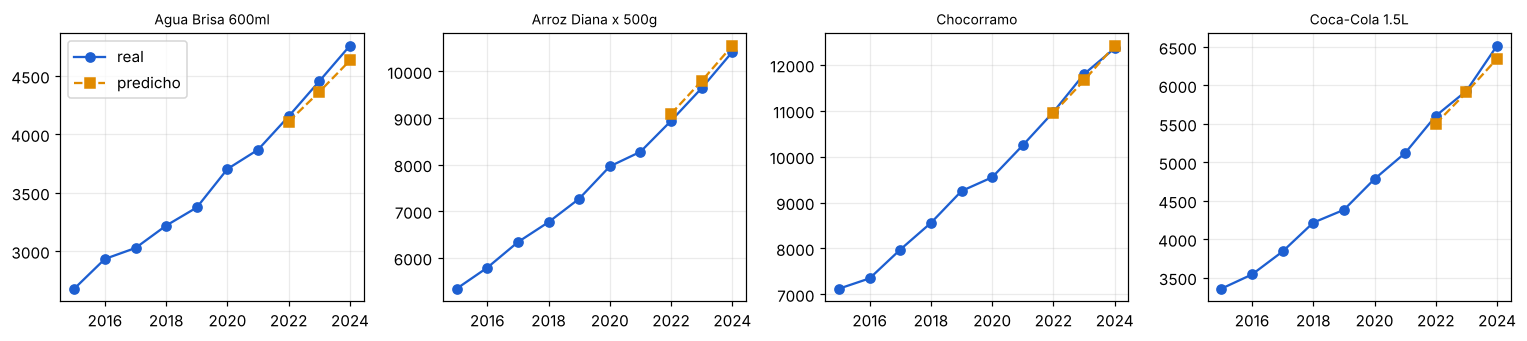

In [10]:
# Gráfica de verificación: histórico vs pronóstico del hold-out para 4 productos
muestra = PRODUCTOS[:4]
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2), sharex=True)
for ax, p in zip(axs, muestra):
    g = df[df.producto == p]
    ax.plot(g.anio, g.precio, "o-", color="#1D5FD1", label="real")
    gp = prueba[prueba.producto == p]
    ax.plot(gp.anio, pred_ho[prueba.producto.values == p], "s--", color="#E08A00", label="predicho")
    ax.set_title(p, fontsize=9)
axs[0].legend(); plt.tight_layout(); plt.show()

## 6. Modelo final y exportación para el backend
El modelo seleccionado se reentrena con **todos** los datos (2015-2024) y se exporta a `modelo_precios.json`. El backend Spring Boot calcula `precio(año) = exp(a + b·(año − 2015))` para cada producto y devuelve el intervalo y el porcentaje predictivo.

In [11]:
assert MEJOR == "Regresión log-lineal por producto", "El exportador está escrito para el modelo log-lineal"
final = PorProducto(log=True).fit(df)

productos = {}
for p in PRODUCTOS:
    m = final.m[p]
    g = df[df.producto == p]
    productos[p] = {
        "a": float(m.intercept_),                              # log(precio) = a + b * año (año sin centrar)
        "b": float(m.coef_[0]),
        "crecimientoAnualPct": float((np.exp(m.coef_[0]) - 1) * 100),
        "ultimoAnio": int(g.anio.max()),
        "ultimoPrecio": float(g.sort_values("anio").precio.iloc[-1]),
        "mapeHoldoutPct": float(det[p]),
    }

mh = holdout[MEJOR]
salida = {
    "version": "2.0",
    "tipoProblema": "Regresión supervisada",
    "modelo": MEJOR,
    "formula": "ln(precio) = a + b · año   →   precio = exp(a + b · año)",
    "variablePredictiva": "precio",
    "variablesPredictoras": ["año", "producto"],
    "dataset": "Productos de Consumo Masivo (Kaggle) · 22 productos · 2015-2024",
    "observaciones": int(len(df)),
    "validacion": "Hold-out temporal: entrenamiento 2015-2021, prueba 2022-2024",
    "metricas": {
        "mae": round(mh["MAE"], 2), "rmse": round(mh["RMSE"], 2),
        "mapePct": round(mh["MAPE"], 3), "r2": round(mh["R2"], 4),
        "porcentajePredictivo": round(100 - mh["MAPE"], 2),
        "sigmaLog": round(SIGMA, 5),
    },
    "comparativa": [
        {"modelo": n, "mae": round(v["MAE"], 2), "rmse": round(v["RMSE"], 2),
         "mapePct": round(v["MAPE"], 3), "r2": round(v["R2"], 4),
         "porcentajePredictivo": round(100 - v["MAPE"], 2)}
        for n, v in sorted(holdout.items(), key=lambda kv: kv[1]["MAPE"])
    ],
    "productos": productos,
}
with open("modelo_precios.json", "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False, indent=2)
print("modelo_precios.json generado:", len(productos), "productos")
print(json.dumps(salida["metricas"], indent=2))

modelo_precios.json generado: 22 productos
{
  "mae": 165.5,
  "rmse": 225.35,
  "mapePct": 2.146,
  "r2": 0.9948,
  "porcentajePredictivo": 97.85,
  "sigmaLog": 0.02867
}


In [12]:
# Pronóstico de ejemplo con el modelo exportado (así lo calcula el backend)
def pronosticar(prod, anio):
    q = salida["productos"][prod]; mu = q["a"] + q["b"] * anio
    z = 1.96 * salida["metricas"]["sigmaLog"]
    return float(np.exp(mu)), float(np.exp(mu - z)), float(np.exp(mu + z))

for a in (2025, 2026, 2027):
    p, lo, hi = pronosticar("Arroz Diana x 500g", a)
    print(a, f"${p:,.0f}  (intervalo 95%: ${lo:,.0f} - ${hi:,.0f})")

try:
    from google.colab import files
    files.download("modelo_precios.json")      # en Colab, descarga el archivo
except ImportError:
    pass

2025 $11,203  (intervalo 95%: $10,591 - $11,850)
2026 $12,048  (intervalo 95%: $11,390 - $12,744)
2027 $12,957  (intervalo 95%: $12,249 - $13,706)


## 7. Conclusiones
* El modelo seleccionado reduce el error medio frente a la regresión lineal global (parecida al modelo Weka original) y explica casi toda la variación de los precios en la validación temporal.
* La red neuronal MLP es competitiva pero no mejora a la regresión por producto con tan pocos datos.
* **Limitaciones:** 10 observaciones por producto, series suaves y un solo hold-out; el modelo no anticipa shocks de inflación. Con más años o variables (ciudad, tienda, inflación) la red neuronal podría superar a la regresión.
* **Integración:** `modelo_precios.json` → Spring Boot (`/api/predict/price` y `/api/prediccion/*`) → web y app móvil.